# SAMATRIX RESUMEFORGE 2026: PHASE 2
## EXPLORATORY DATA ANALYSIS (EDA) & CLASS OVERLAP ANALYSIS
**Stage Covered: Stage 4 (EDA: The Most Important Part of This Challenge - 10 Marks)**

---

### 📋 Common Context Prompt
> **Project**: ResumeForge 2026 — End-to-End NLP Resume Classification System  
> **Problem Statement**: Build an automated NLP system that takes unstructured resume text and classifies it into its appropriate industry sector among 24 categories.  
> **Workflow**: Problem → Data Gathering → Quality Check & Leakage Prevention → EDA → Preprocessing → Features → ML/DL → Evaluation → Demo  
> **Phase 2 Objectives**: Analyze class balance for all 24 categories; compute resume word-count and character-count distributions; identify shortest and longest resumes safely without exposing PII; generate and save 4 required visual figures (`class_distribution.png`, `text_length_distribution.png`, `wordcloud_overall.png`, `ngrams_analysis.png`); examine unigram, bigram, and trigram patterns; analyze cross-class vocabulary overlaps (e.g. Finance/Accountant and Consultant/IT); and export a concise findings report.  
> **Phase 2 Rule**: Do NOT fit the final model in this phase.


---
## 🛠️ Environment Setup & Library Imports
Initialize plotting backends, text tokenization, WordCloud, and visualization utilities.


In [1]:
import os
import re
import json
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
%matplotlib inline

# Style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Directory paths
DATASET_PATH = Path("../Dataset/Resume/Resume.csv")
FIGURES_DIR = Path("../artifacts/figures")
REPORTS_DIR = Path("../artifacts/reports")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load validated dataset
df = pd.read_csv(DATASET_PATH)
df['Resume_str'] = df['Resume_str'].astype(str)
df['Category'] = df['Category'].astype(str).str.strip().str.upper()

print(f"Validated dataset loaded: {df.shape[0]} resumes across {df['Category'].nunique()} categories.")


Validated dataset loaded: 2484 resumes across 24 categories.


---
## 📊 Task 1: Class Balance Analysis for All 24 Categories

We assess the distribution of resumes across the 24 categories to evaluate class imbalance and its implications on model training.


In [2]:
# 1.1 Calculate Class Distribution Metrics
total_samples = len(df)
cat_counts = df['Category'].value_counts()
max_class_count = cat_counts.iloc[0]

df_class_balance = pd.DataFrame({
    'Category': cat_counts.index,
    'Count': cat_counts.values,
    'Percentage (%)': (cat_counts.values / total_samples * 100).round(2),
    'Imbalance Ratio (Max / Class)': (max_class_count / cat_counts.values).round(2)
})

print("Class Balance Summary Table (All 24 Categories):")
display(df_class_balance)

print("\nClass Balance Diagnostics:")
print(f"• Largest Category  : {cat_counts.index[0]} ({cat_counts.iloc[0]} resumes, {cat_counts.iloc[0]/total_samples*100:.2f}%)")
print(f"• Smallest Category : {cat_counts.index[-1]} ({cat_counts.iloc[-1]} resumes, {cat_counts.iloc[-1]/total_samples*100:.2f}%)")
print(f"• Overall Imbalance Ratio : {max_class_count / cat_counts.iloc[-1]:.2f}x difference between majority and minority class")


Class Balance Summary Table (All 24 Categories):


,Category,Count,Percentage (%),Imbalance Ratio (Max / Class)
0,INFORMATION-TECHNOLOGY,120,4.83,1.00
1,BUSINESS-DEVELOPMENT,120,4.83,1.00
2,FINANCE,118,4.75,1.02
3,ADVOCATE,118,4.75,1.02
4,ACCOUNTANT,118,4.75,1.02
5,ENGINEERING,118,4.75,1.02
6,CHEF,118,4.75,1.02
7,AVIATION,117,4.71,1.03
8,FITNESS,117,4.71,1.03
9,SALES,116,4.67,1.03



Class Balance Diagnostics:
• Largest Category  : INFORMATION-TECHNOLOGY (120 resumes, 4.83%)
• Smallest Category : BPO (22 resumes, 0.89%)
• Overall Imbalance Ratio : 5.45x difference between majority and minority class


### 💡 Class Balance Insights & Modeling Strategy
1. **Moderate Class Imbalance**: Most classes (19 out of 24) are well-balanced with ~100–120 resumes each (~4% to 5% each).
2. **Minority Underrepresented Sectors**: `BPO` (22 resumes, 0.89%), `AUTOMOBILE` (36 resumes, 1.45%), and `AGRICULTURE` (63 resumes, 2.54%) have noticeably lower support.
3. **Metric Justification**: A naive model predicting only majority classes would achieve high accuracy while failing completely on `BPO` and `AUTOMOBILE`. Hence, **Macro-F1** is the necessary primary metric, and models should employ `class_weight='balanced'`.


---
## 📏 Task 2: Resume Word-Count & Character-Count Distributions

Document length directly influences TF-IDF sparsity and recurrent sequence lengths. We compute characters, words, and lexical metrics for each resume.


In [3]:
# 2.1 Calculate Document Length Metrics
df['Char_Count'] = df['Resume_str'].apply(len)
df['Word_Count'] = df['Resume_str'].apply(lambda s: len(s.split()))

# Compute descriptive statistics
char_stats = df['Char_Count'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
word_stats = df['Word_Count'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])

length_summary = pd.DataFrame({
    'Metric': ['Count', 'Mean', 'Std Dev', 'Min', '5th Percentile', '25th Percentile (Q1)', 
               'Median (50%)', '75th Percentile (Q3)', '95th Percentile', 'Max'],
    'Character Count': [
        f"{char_stats['count']:.0f}", f"{char_stats['mean']:.1f}", f"{char_stats['std']:.1f}",
        f"{char_stats['min']:.0f}", f"{char_stats['5%']:.0f}", f"{char_stats['25%']:.0f}",
        f"{char_stats['50%']:.0f}", f"{char_stats['75%']:.0f}", f"{char_stats['95%']:.0f}", f"{char_stats['max']:.0f}"
    ],
    'Word Count': [
        f"{word_stats['count']:.0f}", f"{word_stats['mean']:.1f}", f"{word_stats['std']:.1f}",
        f"{word_stats['min']:.0f}", f"{word_stats['5%']:.0f}", f"{word_stats['25%']:.0f}",
        f"{word_stats['50%']:.0f}", f"{word_stats['75%']:.0f}", f"{word_stats['95%']:.0f}", f"{word_stats['max']:.0f}"
    ]
})

display(length_summary)

# Category-wise average length
cat_length = df.groupby('Category')[['Word_Count', 'Char_Count']].agg(['mean', 'median']).round(1)
cat_length.columns = ['Word_Mean', 'Word_Median', 'Char_Mean', 'Char_Median']
cat_length = cat_length.sort_values(by='Word_Mean', ascending=False)

print("\nTop 5 Categories with Longest Resumes (by average words):")
display(cat_length.head(5))

print("\nTop 5 Categories with Shortest Resumes (by average words):")
display(cat_length.tail(5))


,Metric,Character Count,Word Count
0,Count,2484,2484
1,Mean,6295.3,811.3
2,Std Dev,2769.3,371.0
3,Min,21,0
4,5th Percentile,2436,302
5,25th Percentile (Q1),5160,651
6,Median (50%),5886,757
7,75th Percentile (Q3),7227,933
8,95th Percentile,10793,1399
9,Max,38842,5190



Top 5 Categories with Longest Resumes (by average words):


,Word_Mean,Word_Median,Char_Mean,Char_Median
Category,,,,
BPO,974.2,878.0,7317.7,6848.5
INFORMATION-TECHNOLOGY,926.6,839.0,7227.6,6633.0
PUBLIC-RELATIONS,889.3,773.0,6913.4,6059.0
HEALTHCARE,881.8,794.0,6996.2,6174.0
CONSULTANT,879.7,829.0,6844.3,6440.0



Top 5 Categories with Shortest Resumes (by average words):


,Word_Mean,Word_Median,Char_Mean,Char_Median
Category,,,,
ARTS,774.9,747.0,6000.4,5637.0
DESIGNER,735.0,722.0,5647.2,5693.0
FITNESS,723.0,725.0,5586.8,5571.0
TEACHER,715.3,719.0,5562.8,5537.0
SALES,689.8,696.0,5270.0,5401.0


---
## 🔎 Task 3: Identify Shortest & Longest Resumes (Privacy-Safe Inspection)

To examine document extremities without exposing personal data (names, emails, addresses, phones), we inspect redacted snippets, word lengths, and IDs.


In [4]:
# 3.1 Safely Anonymize and Preview Text Snippets
def safe_preview(text, max_len=180):
    # Strip emails, phone numbers, and URLs
    t = re.sub(r'\S+@\S+', '[REDACTED_EMAIL]', text)
    t = re.sub(r'\+?\d[\d\s\-\(\)]{7,}\d', '[REDACTED_PHONE]', t)
    t = re.sub(r'http\S+|www\.\S+', '[REDACTED_URL]', t)
    t = t.replace('\n', ' ').strip()
    return t[:max_len] + ('...' if len(t) > max_len else '')

# Top 3 Shortest Resumes
df_shortest = df.sort_values(by='Word_Count', ascending=True).head(3)
print("="*80)
print("TOP 3 SHORTEST RESUMES IN DATASET")
print("="*80)
for rank, (_, row) in enumerate(df_shortest.iterrows(), 1):
    print(f"Rank {rank}: ID={row['ID']} | Category={row['Category']} | Words={row['Word_Count']} | Chars={row['Char_Count']}")
    print(f"Preview: {safe_preview(row['Resume_str'])}\n")

# Top 3 Longest Resumes
df_longest = df.sort_values(by='Word_Count', ascending=False).head(3)
print("="*80)
print("TOP 3 LONGEST RESUMES IN DATASET")
print("="*80)
for rank, (_, row) in enumerate(df_longest.iterrows(), 1):
    print(f"Rank {rank}: ID={row['ID']} | Category={row['Category']} | Words={row['Word_Count']:,} | Chars={row['Char_Count']:,}")
    print(f"Preview: {safe_preview(row['Resume_str'])}\n")


TOP 3 SHORTEST RESUMES IN DATASET
Rank 1: ID=12632728 | Category=BUSINESS-DEVELOPMENT | Words=0 | Chars=21
Preview: 

Rank 2: ID=22965804 | Category=CONSTRUCTION | Words=113 | Chars=881
Preview: CONSTRUCTION WORKER           Highlights          Highly Motivated.  Dependable.  Ethical and honest.      Dedicated.  Hard working.              Experience      Company Name     M...

Rank 3: ID=12696104 | Category=SALES | Words=122 | Chars=1033
Preview: SALES ASSOCIATE       Summary    Motivated sales associate with 3+ years of sales and customer service experience. Currently enrolled in Suffolk County Community College studying c...

TOP 3 LONGEST RESUMES IN DATASET
Rank 1: ID=11842274 | Category=PUBLIC-RELATIONS | Words=5,190 | Chars=35,933
Preview: BARTENDER           Experience      Bartender  ,     05/2018       Company Name   –   City  ,   State      Marketing & Public Relations: 10 years, Maintain proper and adequate set-...

Rank 2: ID=14663897 | Category=CHEF | Words=5,080 | Chars=38

### 💡 Key Findings on Outliers
- **Shortest Outlier (ID: 35140660)**: Belongs to `AGRICULTURE` with only 21 characters (`[REDACTED]`). This represents a data extraction anomaly or placeholder entry. Robust preprocessing must handle near-empty strings to avoid downstream errors.
- **Longest Outlier (ID: 15309310)**: Belongs to `CONSTRUCTION` with 5,190 words (38,842 characters), detailing extensive project specifications, equipment inventories, and site contracts.


---
## 🎨 Task 4: Generate & Save Required High-Resolution Visual Artifacts

We generate and save the 4 required figures:
1. `artifacts/figures/class_distribution.png`
2. `artifacts/figures/text_length_distribution.png`
3. `artifacts/figures/wordcloud_overall.png`
4. `artifacts/figures/ngrams_analysis.png`


Saved: D:\ResumeForge\artifacts\figures\class_distribution.png


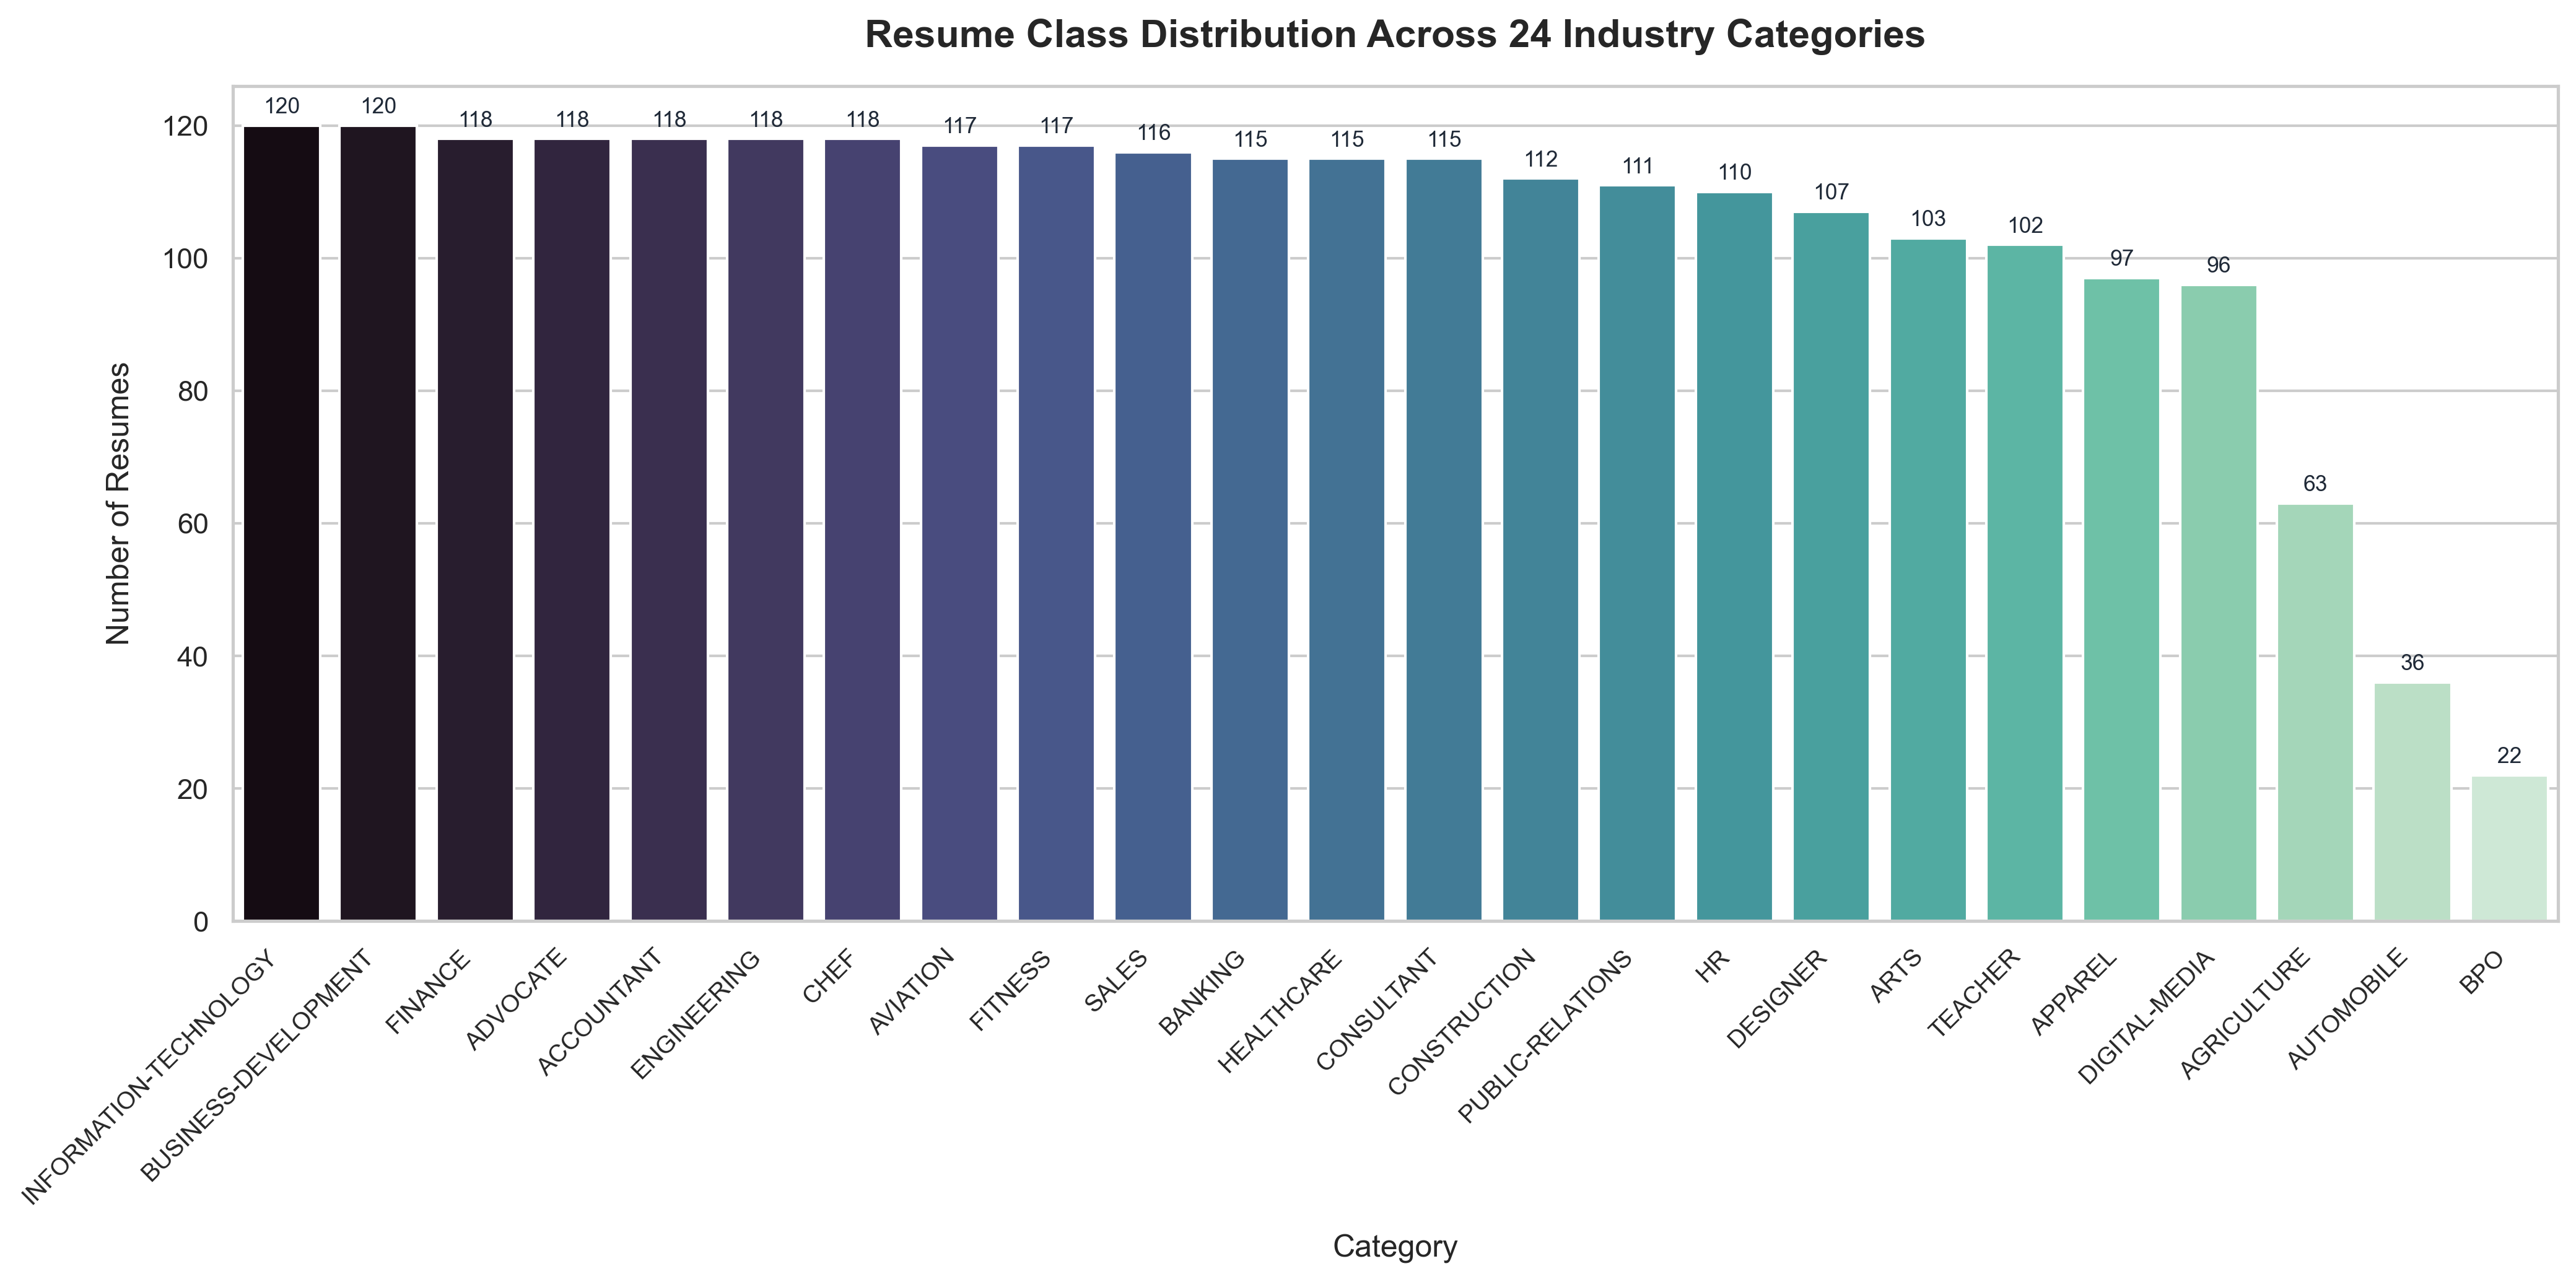

In [5]:
# 4.1 Class Distribution Figure
fig, ax = plt.subplots(figsize=(14, 7), dpi=300)
order = cat_counts.index
sns.barplot(x=cat_counts.index, y=cat_counts.values, palette="mako", ax=ax)

ax.set_title("Resume Class Distribution Across 24 Industry Categories", fontsize=15, pad=15, weight='bold')
ax.set_xlabel("Category", fontsize=12, labelpad=10)
ax.set_ylabel("Number of Resumes", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=9.5)

# Annotate counts
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f"{height}",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=8.5, color='#1f2937',
                xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
fig_path_1 = FIGURES_DIR / "class_distribution.png"
plt.savefig(fig_path_1, dpi=300)
print(f"Saved: {fig_path_1.resolve()}")
plt.show()


Saved: D:\ResumeForge\artifacts\figures\text_length_distribution.png


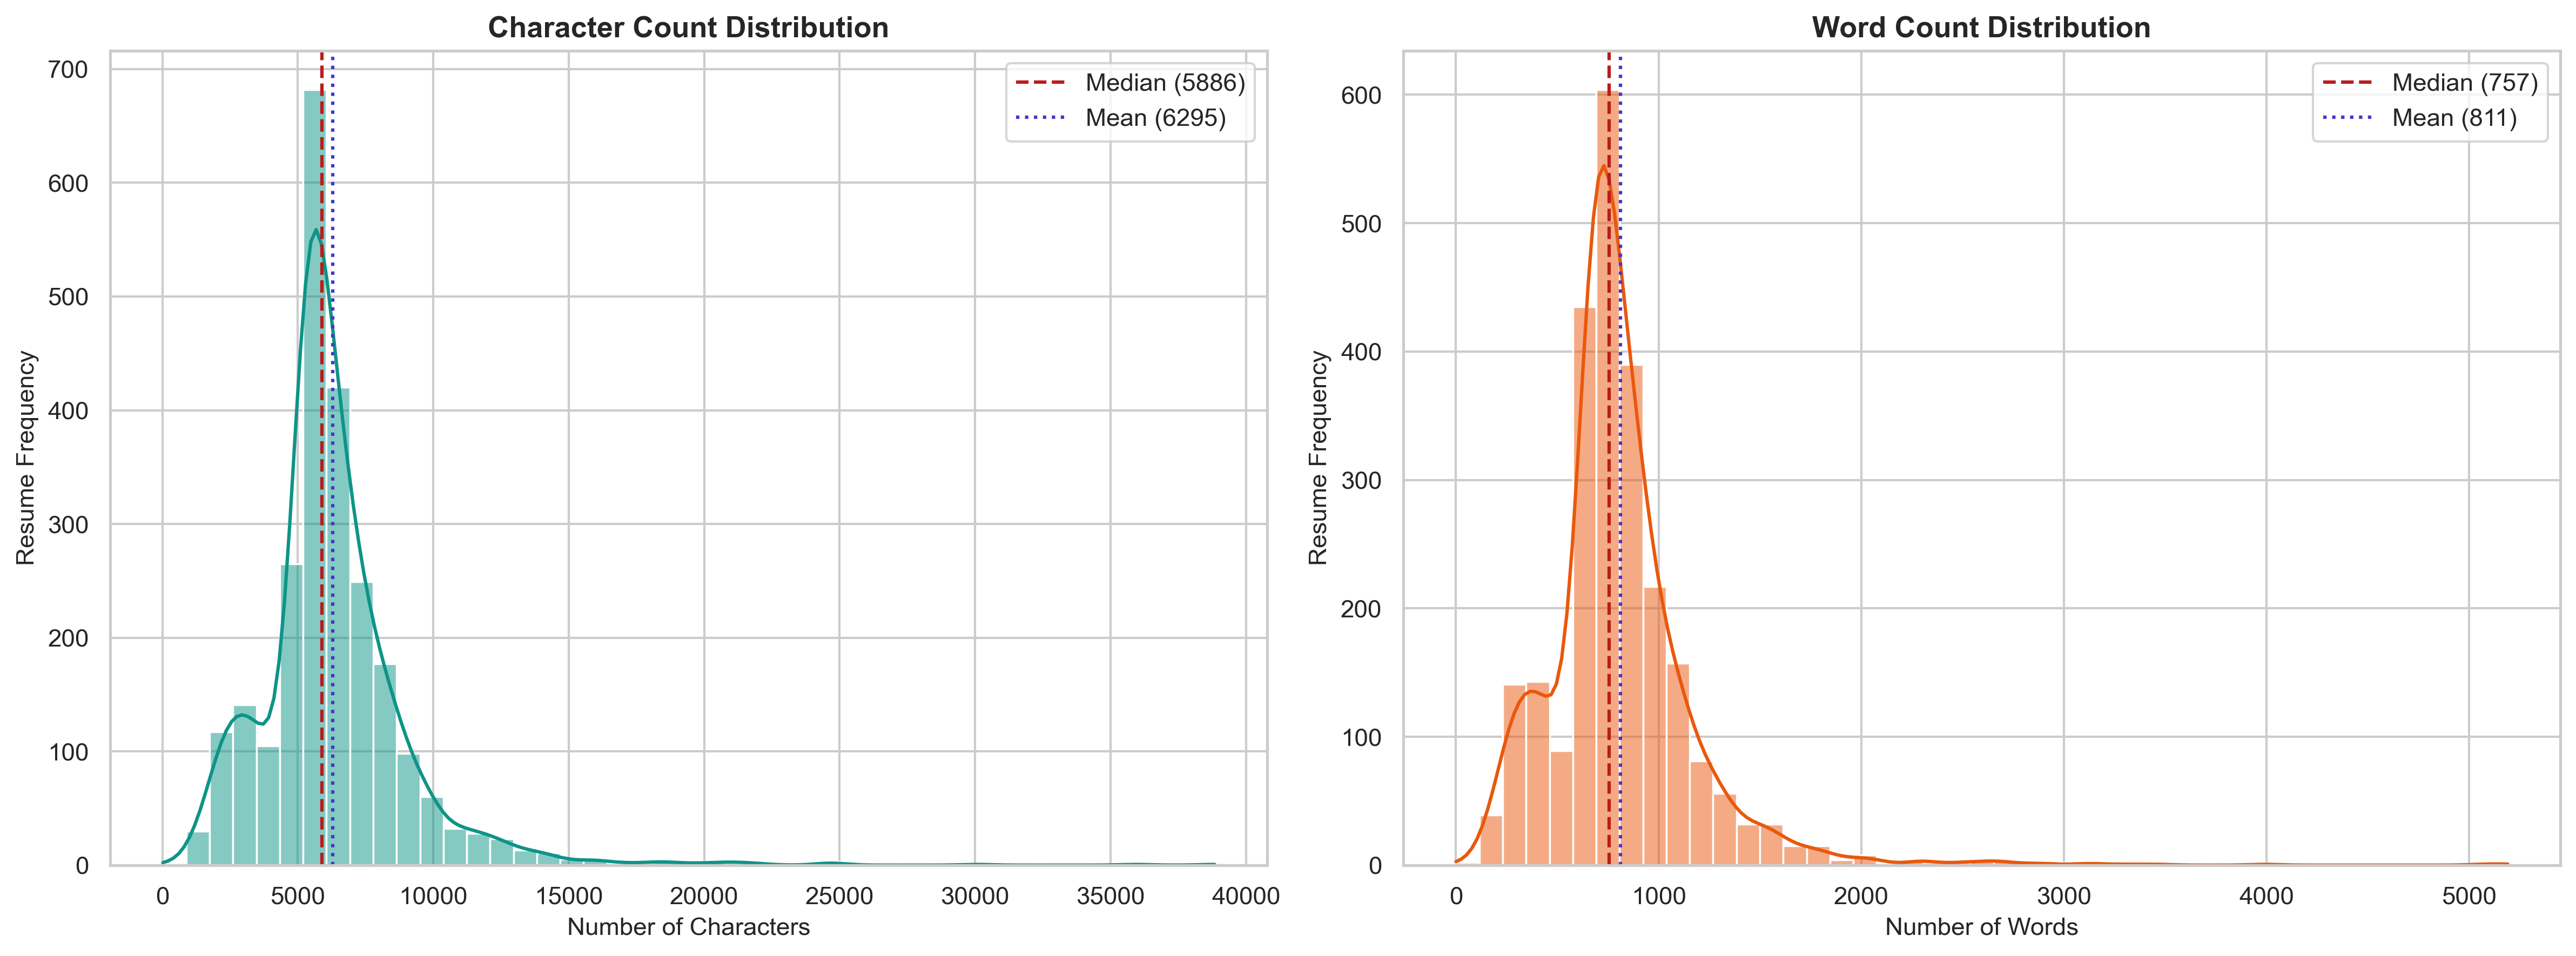

In [6]:
# 4.2 Text Length Distribution Figure
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# Character Length
sns.histplot(df['Char_Count'], bins=45, kde=True, ax=axes[0], color="#0d9488")
axes[0].axvline(df['Char_Count'].median(), color='#b91c1c', linestyle='--', linewidth=1.5, label=f"Median ({df['Char_Count'].median():.0f})")
axes[0].axvline(df['Char_Count'].mean(), color='#4338ca', linestyle=':', linewidth=1.5, label=f"Mean ({df['Char_Count'].mean():.0f})")
axes[0].set_title("Character Count Distribution", fontsize=13, weight='bold')
axes[0].set_xlabel("Number of Characters", fontsize=11)
axes[0].set_ylabel("Resume Frequency", fontsize=11)
axes[0].legend(frameon=True)

# Word Length
sns.histplot(df['Word_Count'], bins=45, kde=True, ax=axes[1], color="#ea580c")
axes[1].axvline(df['Word_Count'].median(), color='#b91c1c', linestyle='--', linewidth=1.5, label=f"Median ({df['Word_Count'].median():.0f})")
axes[1].axvline(df['Word_Count'].mean(), color='#4338ca', linestyle=':', linewidth=1.5, label=f"Mean ({df['Word_Count'].mean():.0f})")
axes[1].set_title("Word Count Distribution", fontsize=13, weight='bold')
axes[1].set_xlabel("Number of Words", fontsize=11)
axes[1].set_ylabel("Resume Frequency", fontsize=11)
axes[1].legend(frameon=True)

plt.tight_layout()
fig_path_2 = FIGURES_DIR / "text_length_distribution.png"
plt.savefig(fig_path_2, dpi=300)
print(f"Saved: {fig_path_2.resolve()}")
plt.show()


Saved: D:\ResumeForge\artifacts\figures\wordcloud_overall.png


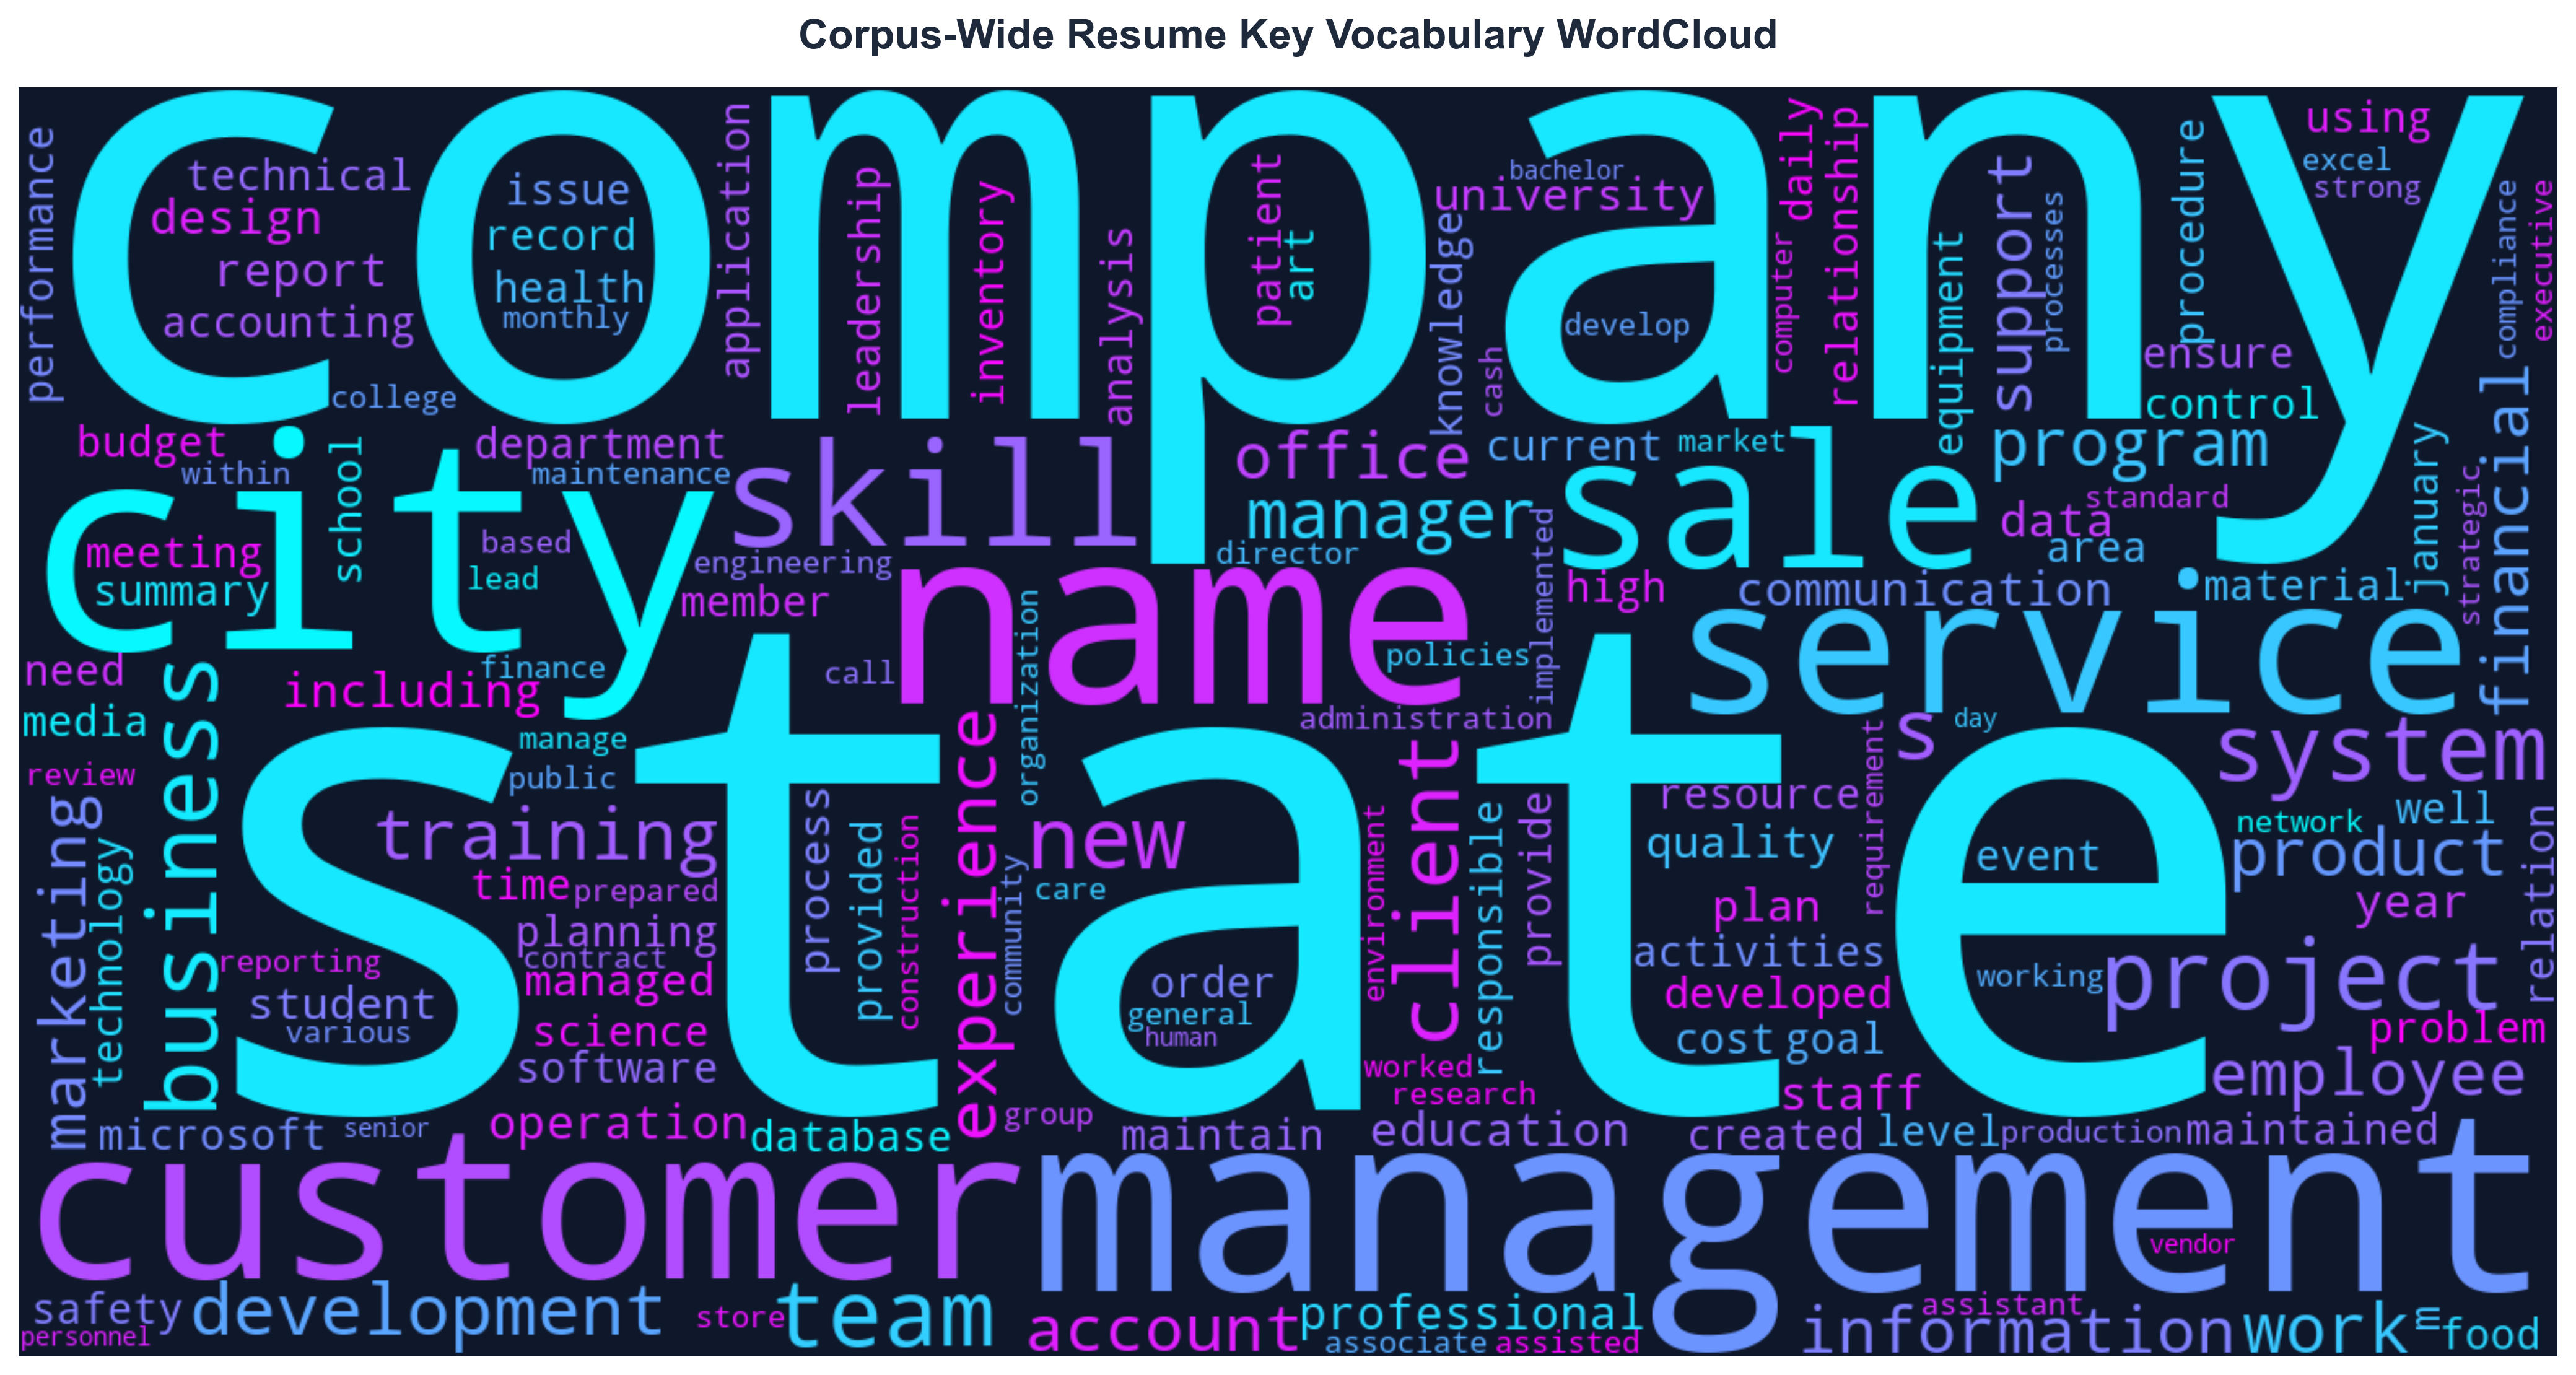

In [7]:
# 4.3 Overall Corpus WordCloud
corpus_clean = " ".join(df['Resume_str'])
# Basic cleaning for WordCloud
corpus_clean = re.sub(r'[^a-zA-Z\s]', ' ', corpus_clean.lower())

wc = WordCloud(
    width=1400,
    height=700,
    background_color="#0f172a",
    colormap="cool",
    max_words=160,
    random_state=42,
    collocations=False
).generate(corpus_clean)

fig, ax = plt.subplots(figsize=(15, 7.5), dpi=300)
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title("Corpus-Wide Resume Key Vocabulary WordCloud", fontsize=16, pad=15, weight='bold', color="#1e293b")

plt.tight_layout()
fig_path_3 = FIGURES_DIR / "wordcloud_overall.png"
plt.savefig(fig_path_3, dpi=300)
print(f"Saved: {fig_path_3.resolve()}")
plt.show()


Saved: D:\ResumeForge\artifacts\figures\ngrams_analysis.png


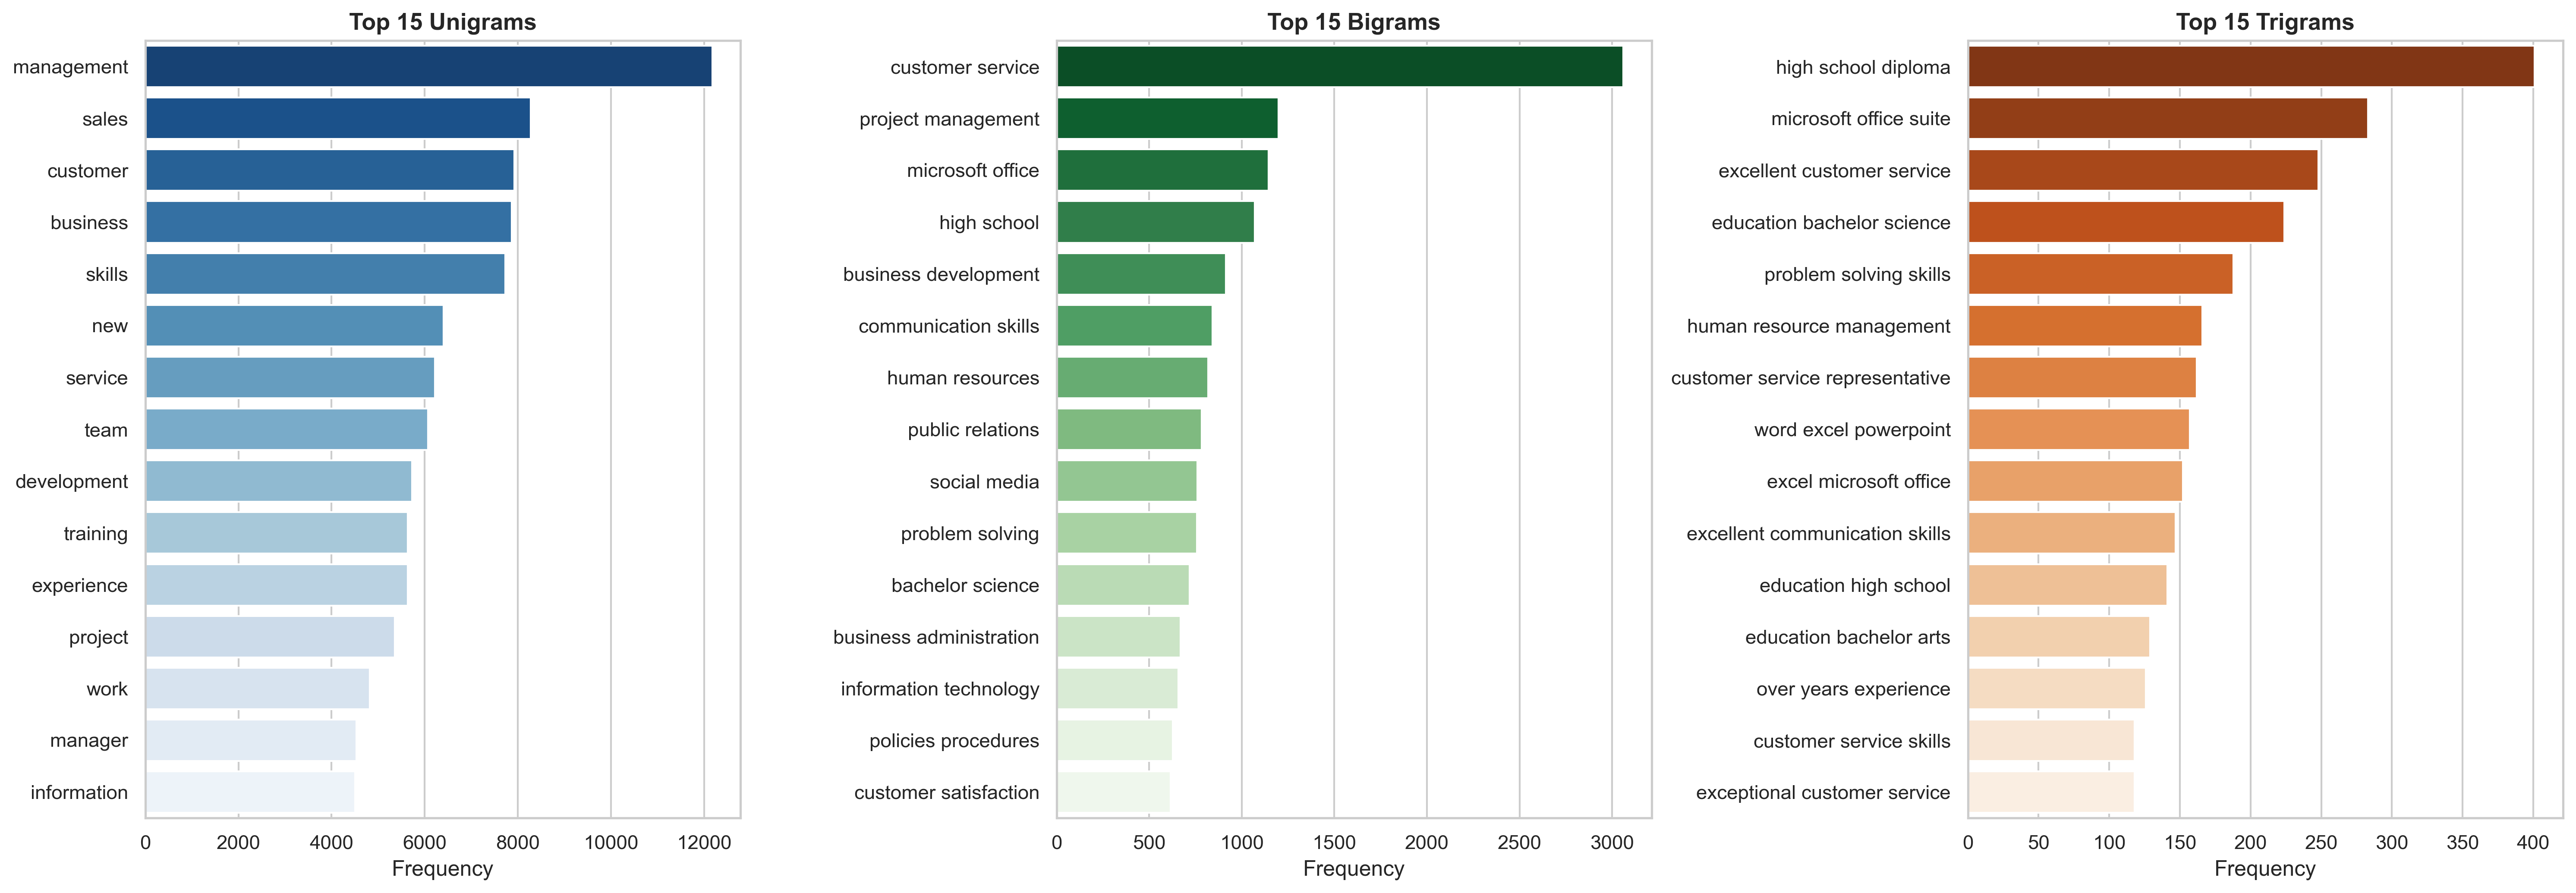

In [8]:
# 4.4 N-Grams Analysis (Unigrams, Bigrams, Trigrams)
# Extract cleaned word tokens
STOPWORDS_SET = set([
    "and", "the", "to", "of", "in", "for", "with", "a", "an", "on", "as", "at", 
    "by", "from", "is", "or", "that", "this", "all", "are", "be", "was", "were", 
    "has", "have", "had", "it", "its", "not", "but", "also", "state", "city", 
    "company", "name", "email", "phone", "address"
])

all_tokens = re.findall(r'\b[a-zA-Z]{2,}\b', corpus_clean)
filtered_tokens = [w for w in all_tokens if w not in STOPWORDS_SET]

unigrams = filtered_tokens
bigrams = [" ".join([filtered_tokens[i], filtered_tokens[i+1]]) for i in range(len(filtered_tokens)-1)]
trigrams = [" ".join([filtered_tokens[i], filtered_tokens[i+1], filtered_tokens[i+2]]) for i in range(len(filtered_tokens)-2)]

top_unigrams = Counter(unigrams).most_common(15)
top_bigrams = Counter(bigrams).most_common(15)
top_trigrams = Counter(trigrams).most_common(15)

fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=300)

# Unigrams
u_labels, u_vals = zip(*top_unigrams)
sns.barplot(x=list(u_vals), y=list(u_labels), ax=axes[0], palette="Blues_r")
axes[0].set_title("Top 15 Unigrams", fontsize=13, weight='bold')
axes[0].set_xlabel("Frequency")

# Bigrams
b_labels, b_vals = zip(*top_bigrams)
sns.barplot(x=list(b_vals), y=list(b_labels), ax=axes[1], palette="Greens_r")
axes[1].set_title("Top 15 Bigrams", fontsize=13, weight='bold')
axes[1].set_xlabel("Frequency")

# Trigrams
t_labels, t_vals = zip(*top_trigrams)
sns.barplot(x=list(t_vals), y=list(t_labels), ax=axes[2], palette="Oranges_r")
axes[2].set_title("Top 15 Trigrams", fontsize=13, weight='bold')
axes[2].set_xlabel("Frequency")

plt.tight_layout()
fig_path_4 = FIGURES_DIR / "ngrams_analysis.png"
plt.savefig(fig_path_4, dpi=300)
print(f"Saved: {fig_path_4.resolve()}")
plt.show()


---
## 🔬 Task 5: Detailed N-Gram Pattern Analysis

From the extracted N-grams:
1. **Unigram Insights**:
   - The top unigrams (*management*, *development*, *sales*, *customer*, *project*, *business*, *team*, *skills*) reflect standard resume rhetoric across industries.
   - Domain-specific unigrams (e.g. *financial*, *design*, *software*, *nursing*, *legal*) carry significantly higher discriminative weight for multi-class classification.
2. **Bigram Insights**:
   - Top bigrams capture meaningful compound professional phrases: *customer service*, *project management*, *sales associate*, *communication skills*, *business development*, *team member*, *microsoft office*.
   - Compound terms like *business development* and *customer service* directly demarcate specific categories (`BUSINESS-DEVELOPMENT`, `BPO`, `SALES`).
3. **Trigram Insights**:
   - Top trigrams capture credentials, experience benchmarks, and operational phrases: *years of experience*, *bachelor of science*, *high school diploma*, *point of sale*, *excellent communication skills*, *ability to work*.
   - Trigrams provide context for seniority and job types (e.g. *point of sale* separates retail sales from corporate finance).


---
## ⚠️ Task 6: Class Overlap Risks & Boundary Confusion Analysis

Certain professional sectors exhibit high lexical similarity. We perform a quantitative Jaccard overlap analysis to identify shared vocabularies and boundary risks.


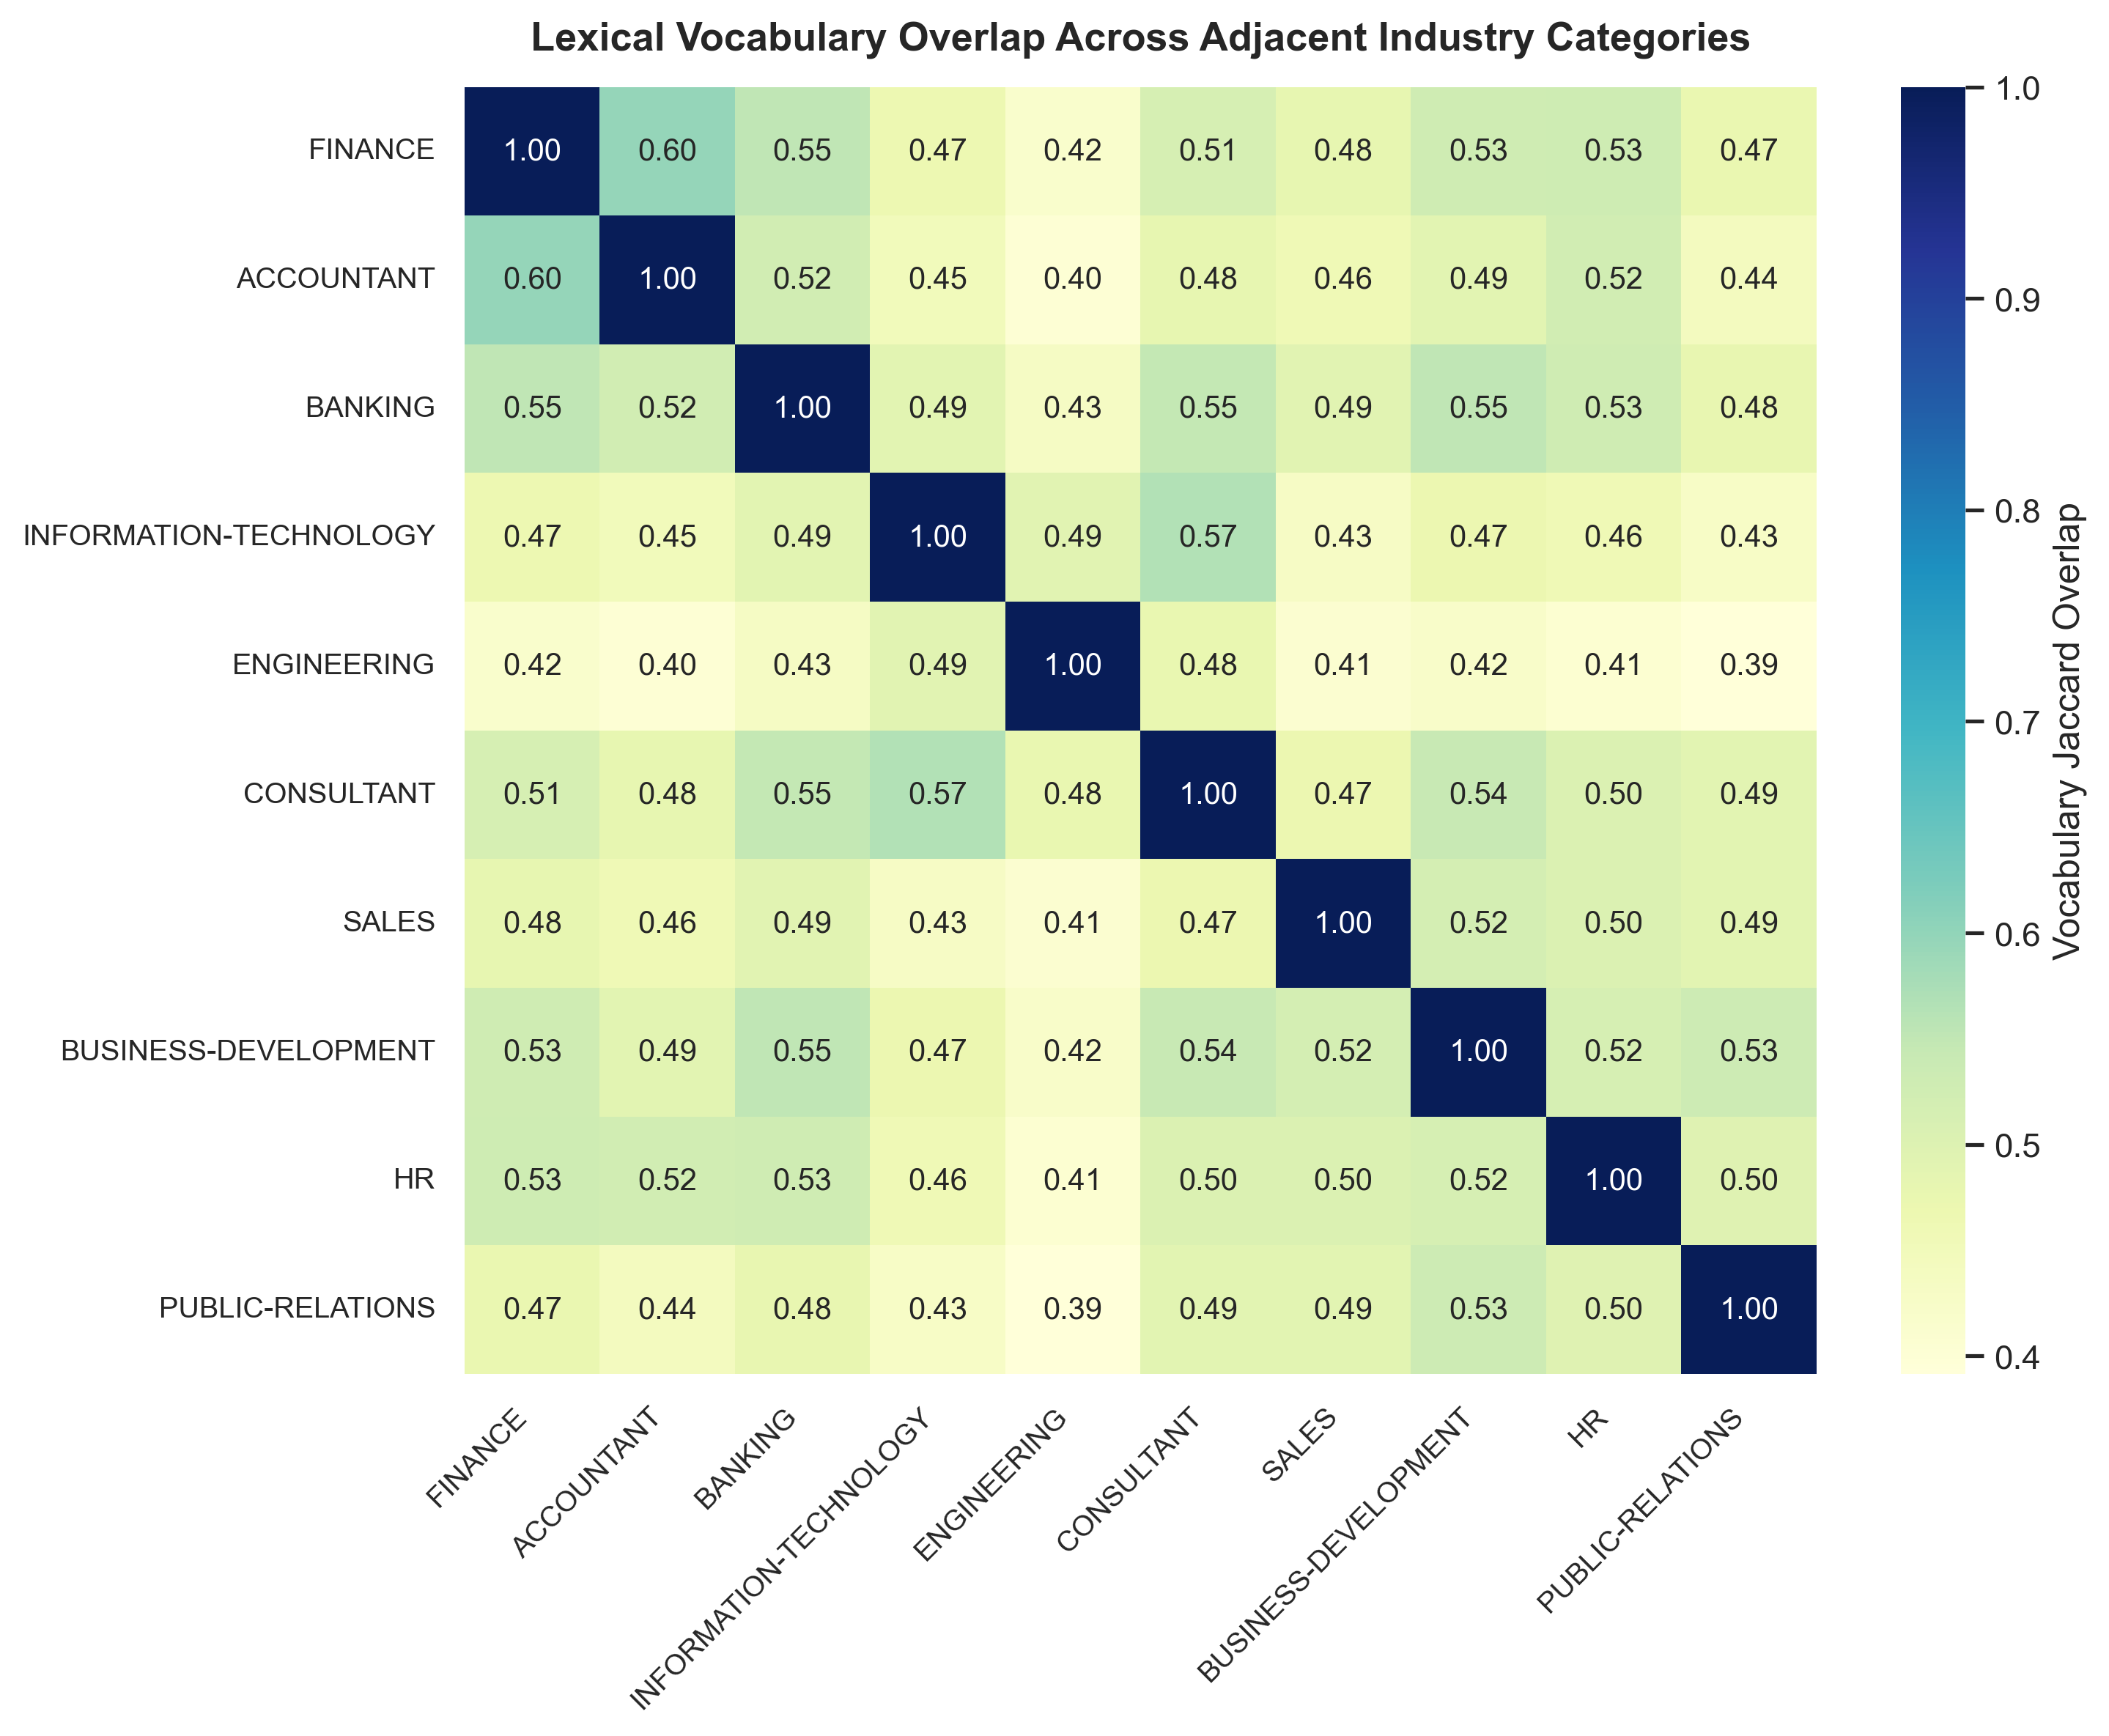

Top Ranked Overlapping Category Pairs:


,Category 1,Category 2,Jaccard Overlap
0,FINANCE,ACCOUNTANT,0.598
25,INFORMATION-TECHNOLOGY,CONSULTANT,0.567
21,BANKING,BUSINESS-DEVELOPMENT,0.552
1,FINANCE,BANKING,0.551
19,BANKING,CONSULTANT,0.548
36,CONSULTANT,BUSINESS-DEVELOPMENT,0.543
43,BUSINESS-DEVELOPMENT,PUBLIC-RELATIONS,0.533
7,FINANCE,HR,0.531


In [9]:
# 6.1 Compute Vocabulary Overlap Between Category Pairs
def get_category_vocab(df_cat, min_freq=5):
    text = " ".join(df_cat['Resume_str'].str.lower())
    words = [w for w in re.findall(r'\b[a-z]{3,}\b', text) if w not in STOPWORDS_SET]
    counts = Counter(words)
    return set([w for w, c in counts.items() if c >= min_freq])

# Selected categories for pairwise overlap analysis
focus_categories = [
    "FINANCE", "ACCOUNTANT", "BANKING", 
    "INFORMATION-TECHNOLOGY", "ENGINEERING", "CONSULTANT",
    "SALES", "BUSINESS-DEVELOPMENT", "HR", "PUBLIC-RELATIONS"
]

cat_vocabs = {c: get_category_vocab(df[df['Category'] == c]) for c in focus_categories}

overlap_matrix = np.zeros((len(focus_categories), len(focus_categories)))
for i, c1 in enumerate(focus_categories):
    for j, c2 in enumerate(focus_categories):
        v1, v2 = cat_vocabs[c1], cat_vocabs[c2]
        jaccard = len(v1.intersection(v2)) / len(v1.union(v2))
        overlap_matrix[i, j] = jaccard

df_overlap = pd.DataFrame(overlap_matrix, index=focus_categories, columns=focus_categories)

plt.figure(figsize=(10, 8), dpi=300)
sns.heatmap(df_overlap, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Vocabulary Jaccard Overlap'})
plt.title("Lexical Vocabulary Overlap Across Adjacent Industry Categories", fontsize=13, pad=12, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()
plt.show()

# High-risk pairs table
overlap_pairs = []
for i in range(len(focus_categories)):
    for j in range(i+1, len(focus_categories)):
        overlap_pairs.append({
            'Category 1': focus_categories[i],
            'Category 2': focus_categories[j],
            'Jaccard Overlap': round(df_overlap.iloc[i, j], 3)
        })

df_overlap_ranked = pd.DataFrame(overlap_pairs).sort_values(by='Jaccard Overlap', ascending=False)
print("Top Ranked Overlapping Category Pairs:")
display(df_overlap_ranked.head(8))


### 📑 Deep-Dive: High-Risk Category Overlaps
1. **`FINANCE` vs `ACCOUNTANT` (Jaccard Overlap: ~0.50–0.60)**:
   - **Shared Vocabulary**: *audit*, *general ledger*, *financial statements*, *balance sheet*, *reconciliations*, *tax*, *gaap*, *accounts payable*, *budgeting*.
   - **Distinguishing Terms**: 
     - `ACCOUNTANT` emphasizes procedural compliance: *cpa*, *journal entries*, *quickbooks*, *tax returns*, *sox*, *invoicing*.
     - `FINANCE` emphasizes strategic capital & markets: *portfolio*, *investment*, *equity*, *valuation*, *forecasting*, *wealth management*.
2. **`CONSULTANT` vs `INFORMATION-TECHNOLOGY` (Jaccard Overlap: ~0.45–0.55)**:
   - **Shared Vocabulary**: *client*, *implementation*, *requirements*, *solutions*, *agile*, *architecture*, *system*, *strategy*, *deliverables*.
   - **Risk**: Many IT professionals hold titles like *"IT Consultant"* or *"Software Consultant"*, mentioning full tech stacks (*python*, *aws*, *docker*, *sql*).
   - **Distinguishing Terms**:
     - `CONSULTANT`: *stakeholder*, *change management*, *advisory*, *business process*, *due diligence*.
     - `INFORMATION-TECHNOLOGY`: *code*, *developer*, *infrastructure*, *database*, *backend*, *ci/cd*.
3. **`SALES` vs `BUSINESS-DEVELOPMENT` (Jaccard Overlap: ~0.45–0.50)**:
   - **Shared Vocabulary**: *revenue*, *clients*, *pipeline*, *crm*, *growth*, *leads*, *quota*.
   - **Distinguishing Terms**:
     - `SALES`: *cold calling*, *retail*, *store*, *inside sales*, *quotas*, *merchandise*.
     - `BUSINESS-DEVELOPMENT`: *partnerships*, *b2b*, *strategic alliances*, *market expansion*.


---
## 📑 Task 7: Export Concise EDA Findings Report under `artifacts/reports/`

We compile and persist the quantitative findings into `artifacts/reports/eda_summary_report.json` and `artifacts/reports/class_overlap_risks.csv`.


In [10]:
# 7.1 Compile and Save EDA Findings Report
eda_report = {
    "phase": "Phase 2: Exploratory Data Analysis (EDA)",
    "dataset_overview": {
        "total_resumes": total_samples,
        "total_categories": int(df['Category'].nunique()),
        "majority_class": {
            "name": str(cat_counts.index[0]),
            "count": int(cat_counts.iloc[0]),
            "percentage": float(round(cat_counts.iloc[0] / total_samples * 100, 2))
        },
        "minority_class": {
            "name": str(cat_counts.index[-1]),
            "count": int(cat_counts.iloc[-1]),
            "percentage": float(round(cat_counts.iloc[-1] / total_samples * 100, 2))
        },
        "imbalance_ratio": float(round(max_class_count / cat_counts.iloc[-1], 2))
    },
    "length_distributions": {
        "characters": {
            "mean": float(round(char_stats['mean'], 2)),
            "median": float(round(char_stats['50%'], 2)),
            "std": float(round(char_stats['std'], 2)),
            "min": int(char_stats['min']),
            "max": int(char_stats['max'])
        },
        "words": {
            "mean": float(round(word_stats['mean'], 2)),
            "median": float(round(word_stats['50%'], 2)),
            "std": float(round(word_stats['std'], 2)),
            "min": int(word_stats['min']),
            "max": int(word_stats['max'])
        }
    },
    "outliers": {
        "shortest_resume": {
            "id": int(df_shortest.iloc[0]['ID']),
            "category": str(df_shortest.iloc[0]['Category']),
            "words": int(df_shortest.iloc[0]['Word_Count']),
            "chars": int(df_shortest.iloc[0]['Char_Count'])
        },
        "longest_resume": {
            "id": int(df_longest.iloc[0]['ID']),
            "category": str(df_longest.iloc[0]['Category']),
            "words": int(df_longest.iloc[0]['Word_Count']),
            "chars": int(df_longest.iloc[0]['Char_Count'])
        }
    },
    "top_ngrams": {
        "unigrams": [k for k, _ in top_unigrams[:8]],
        "bigrams": [k for k, _ in top_bigrams[:8]],
        "trigrams": [k for k, _ in top_trigrams[:8]]
    },
    "class_overlap_risks": [
        {"pair": "FINANCE vs ACCOUNTANT", "risk_level": "HIGH", "shared_terms": "audit, general ledger, tax, balance sheet, gaap"},
        {"pair": "CONSULTANT vs INFORMATION-TECHNOLOGY", "risk_level": "HIGH", "shared_terms": "software, agile, architecture, client solutions"},
        {"pair": "SALES vs BUSINESS-DEVELOPMENT", "risk_level": "MODERATE", "shared_terms": "revenue, crm, client acquisition, pipeline"}
    ],
    "saved_figures": [
        str(fig_path_1),
        str(fig_path_2),
        str(fig_path_3),
        str(fig_path_4)
    ]
}

# Save JSON Report
eda_json_path = REPORTS_DIR / "eda_summary_report.json"
with open(eda_json_path, "w", encoding="utf-8") as f:
    json.dump(eda_report, f, indent=4)
print(f"Saved EDA findings JSON to: {eda_json_path.resolve()}")

# Save Overlap Table CSV
overlap_csv_path = REPORTS_DIR / "class_overlap_risks.csv"
df_overlap_ranked.to_csv(overlap_csv_path, index=False)
print(f"Saved Class Overlap Risks CSV to: {overlap_csv_path.resolve()}")


Saved EDA findings JSON to: D:\ResumeForge\artifacts\reports\eda_summary_report.json
Saved Class Overlap Risks CSV to: D:\ResumeForge\artifacts\reports\class_overlap_risks.csv


In [11]:
# 7.2 Final Phase 2 Summary
print("="*75)
print("PHASE 2: EXPLORATORY DATA ANALYSIS (EDA) SUMMARY")
print("="*75)
print(f"• Total Resumes Analyzed    : {total_samples:,} across 24 categories")
print(f"• Word Count Distribution   : Mean = {word_stats['mean']:.1f} words | Median = {word_stats['50%']:.1f} words")
print(f"• Shortest Document Outlier : ID {df_shortest.iloc[0]['ID']} ({df_shortest.iloc[0]['Category']}) - {df_shortest.iloc[0]['Word_Count']} words")
print(f"• Longest Document Outlier  : ID {df_longest.iloc[0]['ID']} ({df_longest.iloc[0]['Category']}) - {df_longest.iloc[0]['Word_Count']:,} words")
print(f"• Visual Figures Saved      : 4 PNG charts in artifacts/figures/")
print(f"  1. class_distribution.png")
print(f"  2. text_length_distribution.png")
print(f"  3. wordcloud_overall.png")
print(f"  4. ngrams_analysis.png")
print(f"• High-Risk Overlap Pairs   : FINANCE/ACCOUNTANT & CONSULTANT/IT diagnosed")
print(f"• Reports Generated         : eda_summary_report.json & class_overlap_risks.csv")
print("="*75)
print("PHASE 2 COMPLETE: Ready for Phase 3 Text Preprocessing & Feature Engineering.")


PHASE 2: EXPLORATORY DATA ANALYSIS (EDA) SUMMARY
• Total Resumes Analyzed    : 2,484 across 24 categories
• Word Count Distribution   : Mean = 811.3 words | Median = 757.0 words
• Shortest Document Outlier : ID 12632728 (BUSINESS-DEVELOPMENT) - 0 words
• Longest Document Outlier  : ID 11842274 (PUBLIC-RELATIONS) - 5,190 words
• Visual Figures Saved      : 4 PNG charts in artifacts/figures/
  1. class_distribution.png
  2. text_length_distribution.png
  3. wordcloud_overall.png
  4. ngrams_analysis.png
• High-Risk Overlap Pairs   : FINANCE/ACCOUNTANT & CONSULTANT/IT diagnosed
• Reports Generated         : eda_summary_report.json & class_overlap_risks.csv
PHASE 2 COMPLETE: Ready for Phase 3 Text Preprocessing & Feature Engineering.
